# 03 · Relationships and PCA
Questions: which measurements co-vary, and how much does the daily cycle explain? PCA uses complete aligned bins and standardized variables. It cannot infer sensor identity or establish causality.

In [1]:
from pathlib import Path
import sys, json
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'rems_analysis.py').exists()), None)
if root is None:
    raise RuntimeError('Run this notebook inside the RoverWatch repository; see README.md.')
sys.path.insert(0, str(root))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rems_analysis import make_analysis
result, observations = make_analysis()


In [2]:
names=[v['name'] for v in result['channels'].values()]
pd.DataFrame(result['correlation'],index=names,columns=names)

,Air temperature · Boom 1,Air temperature · Boom 2,Atmospheric pressure,Ground brightness temperature
Air temperature · Boom 1,1.000000,0.967658,-0.784053,0.933520
Air temperature · Boom 2,0.967658,1.000000,-0.818552,0.930408
Atmospheric pressure,-0.784053,-0.818552,1.000000,-0.666367
Ground brightness temperature,0.933520,0.930408,-0.666367,1.000000


In [3]:
pd.DataFrame(result['residual_correlation'],index=names,columns=names)

,Air temperature · Boom 1,Air temperature · Boom 2,Atmospheric pressure,Ground brightness temperature
Air temperature · Boom 1,1.000000,0.023502,0.503319,0.274587
Air temperature · Boom 2,0.023502,1.000000,-0.150802,0.162447
Atmospheric pressure,0.503319,-0.150802,1.000000,-0.049971
Ground brightness temperature,0.274587,0.162447,-0.049971,1.000000


Complete bins: 579
Explained variance: [0.8899 0.09   0.0127 0.0074]


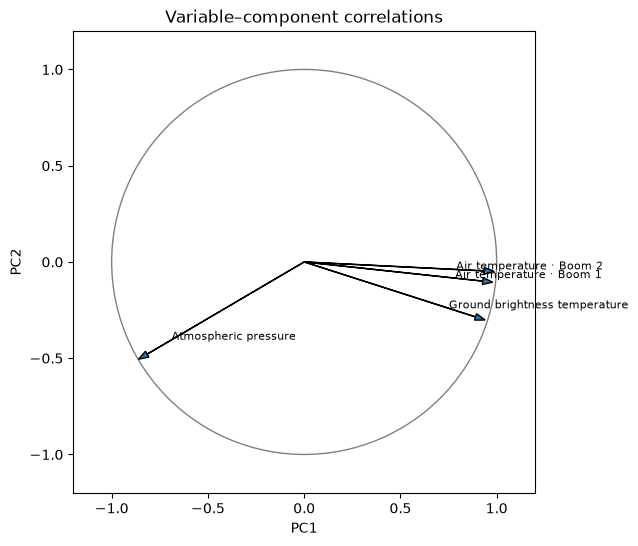

In [4]:
p=result['pca']
print('Complete bins:',p['n'])
print('Explained variance:',np.round(p['explained'],4))
fig,ax=plt.subplots(figsize=(6,6))
ax.add_patch(plt.Circle((0,0),1,fill=False,color='gray'))
for name,(x,y) in zip(names,p['loadings']):
    ax.arrow(0,0,x,y,head_width=.035,length_includes_head=True)
    ax.text(x*.8,y*.8,name,fontsize=8)
ax.set(xlim=(-1.2,1.2),ylim=(-1.2,1.2),xlabel='PC1',ylabel='PC2',title='Variable–component correlations')
ax.set_aspect('equal');plt.show()

PCA is computed by SVD after centering and sample-standard-deviation scaling. The circle coordinates are eigenvector loadings times sqrt(eigenvalue). Similar directions indicate positive association only to the extent captured by the plane. Nearby points in the observation plot are similar profiles, not nearby physical sensors. Temporal dependence, uneven coverage and the short interval limit interpretation; no p-values are claimed.